In [1]:
import pandas as pd
import numpy as np
import keras
from keras import layers
from sklearn.metrics import mean_squared_error, mean_absolute_error
import matplotlib.pyplot as plt
from sklearn.dummy import DummyRegressor
import pandas_market_calendars as mcal

## Data loading

In [2]:
nvidia_stock = pd.read_csv("../../../data/data_stooq/daily/us/nasdaq stocks/2/nvda.us.txt")
nvidia_news = pd.read_csv("../../../data/data_gnews_api/nvidia_news.csv")

## Data preprocessing

basic stock preprocess

In [3]:
## Data preprocessing
rename_dict = {}
for col in nvidia_stock.columns:
    rename_dict[col] = col.strip("<>")
    
# display(rename_dict)
nvidia_stock = nvidia_stock.rename(columns = rename_dict)
# display(nvidia_stock.describe())
# DROPING OPENINT COLUMN
nvidia_stock = nvidia_stock.drop(columns=["OPENINT", "TICKER", "PER", "TIME"])
nvidia_stock["DATE"] = pd.to_datetime(nvidia_stock["DATE"], format="%Y%m%d")
nvidia_stock["LOG_CLOSE_RETURN"] = np.log(nvidia_stock["CLOSE"] / nvidia_stock["CLOSE"].shift(1))

# Drop NaN from LOG_CLOSE_RETURN
nvidia_stock = nvidia_stock.dropna().reset_index(drop=True)

# Add cyclical date features used by models
nvidia_stock['day_of_year'] = nvidia_stock['DATE'].dt.dayofyear
nvidia_stock['month'] = nvidia_stock['DATE'].dt.month
nvidia_stock['day_of_week'] = nvidia_stock['DATE'].dt.dayofweek
nvidia_stock['sin_doy'] = np.sin(2 * np.pi * nvidia_stock['day_of_year'] / 365)
nvidia_stock['cos_doy'] = np.cos(2 * np.pi * nvidia_stock['day_of_year'] / 365)
nvidia_stock['sin_month'] = np.sin(2 * np.pi * nvidia_stock['month'] / 12)
nvidia_stock['cos_month'] = np.cos(2 * np.pi * nvidia_stock['month'] / 12)
nvidia_stock['sin_dow'] = np.sin(2 * np.pi * nvidia_stock['day_of_week'] / 7)
nvidia_stock['cos_dow'] = np.cos(2 * np.pi * nvidia_stock['day_of_week'] / 7)

nvidia_stock.head(2)

,DATE,OPEN,HIGH,LOW,CLOSE,VOL,LOG_CLOSE_RETURN,day_of_year,month,day_of_week,sin_doy,cos_doy,sin_month,cos_month,sin_dow,cos_dow
0,1999-01-25,0.040586,0.041963,0.037602,0.041499,139413824,0.098620,25,1,0,0.417194,0.908818,0.5,0.866025,0.000000,1.00000
1,1999-01-26,0.041963,0.042876,0.037839,0.038287,93919355,-0.080567,26,1,1,0.432776,0.901502,0.5,0.866025,0.781831,0.62349


basic news preprocess

In [4]:
import pandas_market_calendars as mcal

nvidia_news = nvidia_news.drop(columns=["url", "source_url", "image_url", "query"])
nvidia_news["published_at"] = pd.to_datetime(nvidia_news["published_at"], format="ISO8601")
nvidia_news = nvidia_news.rename(columns={"published_at": "date"})

# --- align news timestamps to NVDA trading days (NASDAQ, US/Eastern) ---
sched_index = mcal.get_calendar("NASDAQ").schedule(start_date="1999-01-01", end_date="2027-01-01").index

if sched_index.tz is not None:
    sched_index = sched_index.tz_localize(None)
trading_days = set(sched_index.normalize())

ts_et = nvidia_news["date"].dt.tz_convert("America/New_York")
is_after_close = (ts_et.dt.time >= pd.Timestamp("16:00").time()).astype(int)
day_et = ts_et.dt.normalize().dt.tz_localize(None) + pd.to_timedelta(is_after_close, unit="D")

nvidia_news["trading_day"] = [
    next(d for d in pd.date_range(day, periods=10) if d in trading_days)
    for day in day_et
]

nvidia_news["trading_day"] = pd.to_datetime(nvidia_news["trading_day"], format="%Y%m%d")

nvidia_news.head(2)

,date,title,description,content,source_name,week_start,week_end,trading_day
0,2020-01-07 14:33:08+00:00,"TiVo Stream 4K uses Android TV, announced at C...",TiVo Stream 4K was officially announced at CES...,CES 2020 rolls on this morning as TiVo has unv...,9to5Toys,2020-01-01,2020-01-07,2020-01-07
1,2020-01-09 18:48:47+00:00,Every new Android TV announced at CES 2020,"Just like any year, this year's CES has focuse...","Just like any year, this year's CES has focuse...",Android Police,2020-01-08,2020-01-14,2020-01-09


truncating both ticker and stock data to match

In [5]:
# Identify min and max dates for both datasets
news_min = nvidia_news["trading_day"].min()
news_max = nvidia_news["trading_day"].max()
stock_min = nvidia_stock["DATE"].min()
stock_max = nvidia_stock["DATE"].max()

print("nvidia_news date.min(), date.max():", news_min, news_max)
print("nvidia_stock DATE.min(), DATE.max():", stock_min, stock_max)

# Compute overlapping time range and truncate both DataFrames to that range
start = max(news_min, stock_min)
end = min(news_max, stock_max)
print("Overlapping range:", start, end)

nvidia_news = nvidia_news[(nvidia_news["trading_day"] >= start) & (nvidia_news["trading_day"] <= end)].reset_index(drop=True)
nvidia_stock = nvidia_stock[(nvidia_stock["DATE"] >= start) & (nvidia_stock["DATE"] <= end)].reset_index(drop=True)

nvidia_news.head(2)
nvidia_stock.head(2)

nvidia_news date.min(), date.max(): 2020-01-07 00:00:00 2026-05-18 00:00:00
nvidia_stock DATE.min(), DATE.max(): 1999-01-25 00:00:00 2026-02-20 00:00:00
Overlapping range: 2020-01-07 00:00:00 2026-02-20 00:00:00


,DATE,OPEN,HIGH,LOW,CLOSE,VOL,LOG_CLOSE_RETURN,day_of_year,month,day_of_week,sin_doy,cos_doy,sin_month,cos_month,sin_dow,cos_dow
0,2020-01-07,5.93024,6.01934,5.88510,5.97338,320543948,0.012040,7,1,1,0.120208,0.992749,0.5,0.866025,0.781831,0.623490
1,2020-01-08,5.96910,6.02601,5.92905,5.98467,278402946,0.001888,8,1,2,0.137279,0.990532,0.5,0.866025,0.974928,-0.222521


## Prepare dataset

In [6]:
# Build aligned stock-news windows: returns (X_stock, X_news, y)
def make_windows_with_news(
    stock_df: pd.DataFrame,
    news_df: pd.DataFrame,
    feature_cols: list,
    target_col: str,
    window_days: int,
    horizon_days: int = 1,
    stock_date_col: str = "DATE",
    news_date_col: str = "trading_day",
    news_text_col: str = None,
    aggregate: str = "count",
):
    """Create paired windows of stock features and news aggregated by stock-day.

    Args:
      stock_df: DataFrame with a stock date column (default 'DATE').
      news_df: DataFrame with a news date column (default 'trading_day').
      feature_cols: list of stock feature column names used for X_stock.
      target_col: stock column used as target (e.g. 'LOG_CLOSE_RETURN').
      window_days: number of days in the context window.
      horizon_days: prediction horizon in days.
      news_text_col: if provided, X_news will contain lists of article texts per day; otherwise counts.
      aggregate: 'count' or 'count_norm' (normalized by max) when news_text_col is None.

    Returns:
      X_stock: ndarray (samples, window_days, n_features)
      X_news: ndarray (samples, window_days) of counts or object-array of lists when text requested
      y: ndarray (samples,)
    """
    stock = stock_df.copy().reset_index(drop=True)
    news = news_df.copy().reset_index(drop=True)

    # Ensure datetime normalization
    stock_dates = pd.to_datetime(stock[stock_date_col]).dt.normalize()
    news[news_date_col] = pd.to_datetime(news[news_date_col]).dt.normalize()

    # Group news by date
    if news_text_col is None:
        news_counts = news.groupby(news[news_date_col]).size()
        news_counts.index = pd.to_datetime(news_counts.index).normalize()
        news_map = news_counts.to_dict()
    else:
        grouped = news.groupby(news[news_date_col])[news_text_col].apply(list)
        grouped.index = pd.to_datetime(grouped.index).normalize()
        news_map = grouped.to_dict()

    values = stock[feature_cols].to_numpy()
    targets = stock[target_col].to_numpy()

    n = len(stock)
    Xs, Xn, Ys = [], [], []

    last_start = n - window_days - horizon_days
    for start in range(0, last_start + 1):
        context_end = start + window_days
        last_context_idx = context_end - 1

        context_vals = values[start:context_end]
        target = targets[last_context_idx + 1 : last_context_idx + 1 + horizon_days].sum()

        context_dates = stock_dates.iloc[start:context_end]
        if news_text_col is None:
            news_vector = np.array([news_map.get(d, 0) for d in context_dates])
            if aggregate == "count_norm":
                maxv = news_vector.max() if news_vector.size else 1
                news_vector = news_vector / (maxv if maxv != 0 else 1)
        else:
            news_vector = [news_map.get(d, []) for d in context_dates]

        Xs.append(context_vals)
        Xn.append(news_vector)
        Ys.append(target)

    Xs = np.array(Xs)
    if news_text_col is None:
        Xn = np.array(Xn)
    else:
        Xn = np.array(Xn, dtype=object)
    Ys = np.array(Ys)

    return Xs, Xn, Ys

# Example: build and save windows arrays
features = ['LOG_CLOSE_RETURN', 'sin_doy', 'cos_doy', 'sin_month', 'cos_month', 'sin_dow', 'cos_dow']
Xs, Xn, Ys = make_windows_with_news(nvidia_stock, nvidia_news, features, 'LOG_CLOSE_RETURN', window_days=30)
print('Xs shape:', Xs.shape)
print('Xn shape:', Xn.shape)
print('Ys shape:', Ys.shape)

Xs shape: (1509, 30, 7)
Xn shape: (1509, 30)
Ys shape: (1509,)


# LLM features

In [7]:
from pathlib import Path
import sys

# notebook is in .../news_with_feature_engineering/notebooks
# parent() points to .../news_with_feature_engineering which contains `utils`
sys.path.insert(0, str(Path.cwd().parent.resolve()))

from utils.llm_news_features import extract_daily_news_features
from utils.rolling_news_features import build_rolling_news_features

# nvidia_news already has the trading_day column from your mcal alignment step
daily_features = extract_daily_news_features(
    nvidia_news, date_col="trading_day", text_col="content", title_col="title"
)

rolling_features = build_rolling_news_features(
    daily_features,
    news_start_date=nvidia_news["trading_day"].min(),
    news_end_date=nvidia_news["trading_day"].max(),
    window_days=5,
)

# merge onto stock df exactly like NEWS_ARTICLE_COUNT_5D before
nvidia_stock = nvidia_stock.merge(
    rolling_features, left_on="DATE", right_on="DATE", how="inner"
)

653 unique days with news, 653 already cached


In [8]:
## ============================================================
## Time-based split (80/10/10) — same rule as track 1/2, now on the
## nvidia_stock df that already has rolling news features merged in
## ============================================================
nvidia_stock = nvidia_stock.sort_values("DATE").reset_index(drop=True)
 
n = len(nvidia_stock)
train_size = int(n * 0.8)
val_size = int(n * 0.1)
 
train_nvidia_stock = nvidia_stock.iloc[:train_size].copy()
validation_nvidia_stock = nvidia_stock.iloc[train_size:train_size + val_size].copy()
test_nvidia_stock = nvidia_stock.iloc[train_size + val_size:].copy()
 
print(f"Dataset size: {len(nvidia_stock)}")
print(f"Train size: {len(train_nvidia_stock)}")
print(f"Validation size: {len(validation_nvidia_stock)}")
print(f"Test size: {len(test_nvidia_stock)}")
print(f"Train date range: {train_nvidia_stock['DATE'].min()} to {train_nvidia_stock['DATE'].max()}")
print(f"Validation date range: {validation_nvidia_stock['DATE'].min()} to {validation_nvidia_stock['DATE'].max()}")
print(f"Test date range: {test_nvidia_stock['DATE'].min()} to {test_nvidia_stock['DATE'].max()}")

Dataset size: 1536
Train size: 1228
Validation size: 153
Test size: 155
Train date range: 2020-01-08 00:00:00 to 2024-11-21 00:00:00
Validation date range: 2024-11-22 00:00:00 to 2025-07-08 00:00:00
Test date range: 2025-07-09 00:00:00 to 2026-02-18 00:00:00


In [9]:
## ============================================================
## Feature scaling — StandardScaler, applied ONLY to the article-count
## column. Everything else (returns, cyclical, sentiment/materiality
## scores) is already roughly comparable scale (small values, mostly
## bounded near ±1) — only NEWS_ARTICLE_COUNT_5D is the outlier (raw
## sums that can run into the tens/hundreds), which is what was likely
# ## driving the RNN's oversized predictions.
# ## ============================================================
from sklearn.preprocessing import StandardScaler
 
count_col = [f"NEWS_ARTICLE_COUNT_5D"]
 
scaler = StandardScaler()
 
# fit on train, transform train
train_nvidia_stock[count_col] = scaler.fit_transform(train_nvidia_stock[count_col])
 
# transform-only (no fitting) on val/test, using train's fitted mean/std
validation_nvidia_stock[count_col] = scaler.transform(validation_nvidia_stock[count_col])
test_nvidia_stock[count_col] = scaler.transform(test_nvidia_stock[count_col])
 
print(train_nvidia_stock[count_col].describe())  # sanity check: train should now have mean~0, std~1

       NEWS_ARTICLE_COUNT_5D
count           1.228000e+03
mean            8.100650e-17
std             1.000407e+00
min            -1.224591e+00
25%            -1.133684e+00
50%             4.117505e-01
75%             1.048106e+00
max             1.593553e+00


In [10]:
## ============================================================
## Windowing — same function as track 1/2 (horizon-sum fix included)
## ============================================================
def make_windows(
    df: pd.DataFrame,
    feature_cols: list[str],
    target_col: str,
    window_days: int,
    horizon_days: int = 1,
) -> tuple[np.ndarray, np.ndarray]:
    values = df[feature_cols].to_numpy()
    targets = df[target_col].to_numpy()
 
    n = len(df)
    X, y = [], []
 
    last_start = n - window_days - horizon_days
    for start in range(0, last_start + 1):
        context_end = start + window_days  # exclusive
        last_context_idx = context_end - 1
 
        context = values[start:context_end]
        target = targets[last_context_idx + 1 : last_context_idx + 1 + horizon_days].sum()
 
        X.append(context)
        y.append(target)
 
    return np.array(X), np.array(y)
 
## news rolling feature column names — must match what build_rolling_news_features
## produced (adjust WINDOW_DAYS suffix below if you used a different window_days)
NEWS_WINDOW = 5
news_feature_cols = [
    f"NEWS_SENTIMENT_MEAN_{NEWS_WINDOW}D",
    f"NEWS_CONFIDENCE_MEAN_{NEWS_WINDOW}D",
    f"NEWS_DISAGREEMENT_MAX_{NEWS_WINDOW}D",
    f"NEWS_MATERIALITY_MAX_{NEWS_WINDOW}D",
    f"NEWS_HAS_SURPRISE_{NEWS_WINDOW}D",
    f"NEWS_HAS_GUIDANCE_CHANGE_{NEWS_WINDOW}D",
    f"NEWS_ARTICLE_COUNT_{NEWS_WINDOW}D",
]
 
features_chosen = [
    'LOG_CLOSE_RETURN',
    'sin_doy', 'cos_doy', 'sin_month', 'cos_month', 'sin_dow', 'cos_dow',
] + news_feature_cols
 
WINDOW_DAYS = 30  # price/context window — kept at 30 for comparability with track 1/2
 
X_train, y_train = make_windows(df=train_nvidia_stock, feature_cols=features_chosen,
                                 target_col='LOG_CLOSE_RETURN', window_days=WINDOW_DAYS)
X_val, y_val = make_windows(df=validation_nvidia_stock, feature_cols=features_chosen,
                             target_col='LOG_CLOSE_RETURN', window_days=WINDOW_DAYS)
X_test, y_test = make_windows(df=test_nvidia_stock, feature_cols=features_chosen,
                               target_col='LOG_CLOSE_RETURN', window_days=WINDOW_DAYS)
 
print(type(X_train))
print("X_train shape:", X_train.shape)  # (samples, window_days, n_features)
print("y_train shape:", y_train.shape)

<class 'numpy.ndarray'>
X_train shape: (1198, 30, 14)
y_train shape: (1198,)


In [11]:
## ============================================================
## Model definition — identical architecture to track 1/2, just with
## the news feature channels added to the input dimension
## ============================================================
n_features = X_train.shape[-1]
 
RNN_model = keras.Sequential([
    layers.Input(shape=(WINDOW_DAYS, n_features)),
    layers.SimpleRNN(32),
    layers.Dense(16, activation="relu"),
    layers.Dense(1)
])
RNN_model.compile(optimizer="adam", loss="mse")
 
LSTM_model = keras.Sequential([
    layers.Input(shape=(WINDOW_DAYS, n_features)),
    layers.LSTM(32),
    layers.Dense(16, activation="relu"),
    layers.Dense(1)
])
LSTM_model.compile(optimizer="adam", loss="mse")

In [12]:
## ============================================================
## Training
## ============================================================
print("Training RNN...")
rnn_history = RNN_model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=32,
)
 
print("Training LSTM...")
lstm_history = LSTM_model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=32,
)

Training RNN...
Epoch 1/20
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.2347 - val_loss: 0.0573
Epoch 2/20
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0263 - val_loss: 0.0371
Epoch 3/20
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0179 - val_loss: 0.0303
Epoch 4/20
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0140 - val_loss: 0.0259
Epoch 5/20
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0115 - val_loss: 0.0216
Epoch 6/20
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0097 - val_loss: 0.0190
Epoch 7/20
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0085 - val_loss: 0.0165
Epoch 8/20
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0073 - val_loss: 0.0152
Epoch 9/20
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0066 - val_loss: 0.0135
Epoch 10/20
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0059 - val_loss: 0.0127
Epoch 11/20
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0055 - val_loss: 0.0118
Epoch 12/20
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss:

RNN         - MSE: 0.008978, MAE: 0.074151
LSTM        - MSE: 0.000949, MAE: 0.024122
Dummy (mean)- MSE: 0.000479, MAE: 0.017033


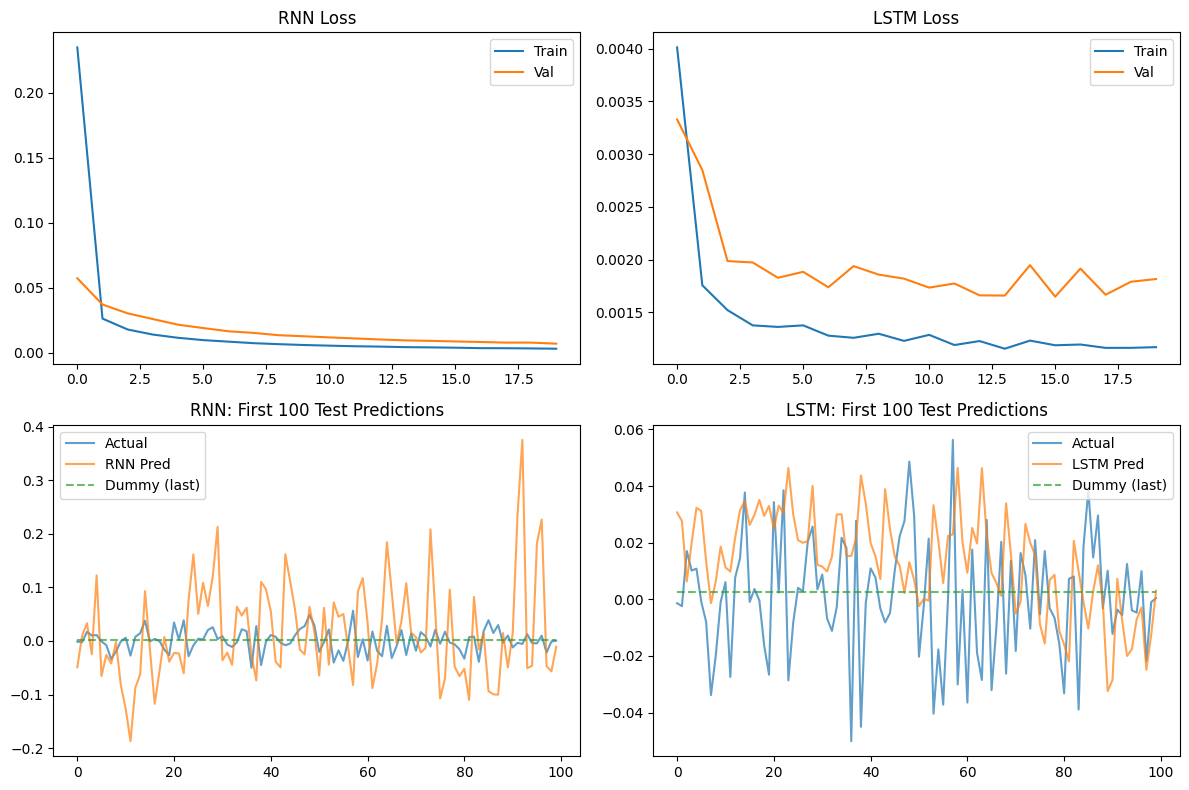

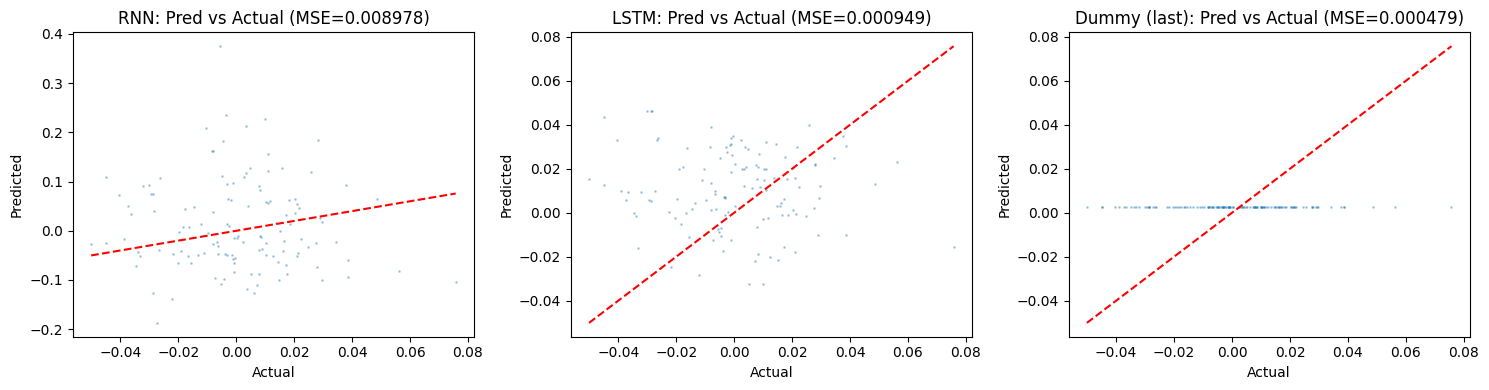

RNN pred vs y_test correlation: -0.04525014939347607
LSTM pred vs y_test correlation: -0.08674883140760693
Actual test-set movement distribution:
  Up:   49.60%
  Down: 50.40%
  Flat: 0.00%
RNN          - Directional accuracy: 49.60% (predicted up: 45.60%, down: 54.40%)
LSTM         - Directional accuracy: 48.00% (predicted up: 72.80%, down: 27.20%)
Dummy (mean) - Directional accuracy: 49.60% (predicted up: 100.00%, down: 0.00%)


In [13]:
## ============================================================
## Evaluation & Visualization — identical structure to track 1/2
## ============================================================
dummy_mean = DummyRegressor(strategy="mean")  # predict mean of train
dummy_mean.fit(X_train, y_train)
 
dummy_mean_pred = dummy_mean.predict(X_test)
 
# Model predictions
rnn_pred = RNN_model.predict(X_test, verbose='0').flatten()
lstm_pred = LSTM_model.predict(X_test, verbose='0').flatten()
 
# Metrics
rnn_mse = mean_squared_error(y_test, rnn_pred)
rnn_mae = mean_absolute_error(y_test, rnn_pred)
lstm_mse = mean_squared_error(y_test, lstm_pred)
lstm_mae = mean_absolute_error(y_test, lstm_pred)
dummy_mean_mse = mean_squared_error(y_test, dummy_mean_pred)
dummy_mean_mae = mean_absolute_error(y_test, dummy_mean_pred)
 
print(f"RNN         - MSE: {rnn_mse:.6f}, MAE: {rnn_mae:.6f}")
print(f"LSTM        - MSE: {lstm_mse:.6f}, MAE: {lstm_mae:.6f}")
print(f"Dummy (mean)- MSE: {dummy_mean_mse:.6f}, MAE: {dummy_mean_mae:.6f}")
 
# Plot training history
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
 
# Loss curves
axes[0, 0].plot(rnn_history.history['loss'], label='Train')
axes[0, 0].plot(rnn_history.history['val_loss'], label='Val')
axes[0, 0].set_title('RNN Loss')
axes[0, 0].legend()
 
axes[0, 1].plot(lstm_history.history['loss'], label='Train')
axes[0, 1].plot(lstm_history.history['val_loss'], label='Val')
axes[0, 1].set_title('LSTM Loss')
axes[0, 1].legend()
 
# Predictions vs Actual
axes[1, 0].plot(y_test[:100], label='Actual', alpha=0.7)
axes[1, 0].plot(rnn_pred[:100], label='RNN Pred', alpha=0.7)
axes[1, 0].plot(dummy_mean_pred[:100], label='Dummy (last)', alpha=0.7, linestyle='--')
axes[1, 0].set_title('RNN: First 100 Test Predictions')
axes[1, 0].legend()
 
axes[1, 1].plot(y_test[:100], label='Actual', alpha=0.7)
axes[1, 1].plot(lstm_pred[:100], label='LSTM Pred', alpha=0.7)
axes[1, 1].plot(dummy_mean_pred[:100], label='Dummy (last)', alpha=0.7, linestyle='--')
axes[1, 1].set_title('LSTM: First 100 Test Predictions')
axes[1, 1].legend()
 
plt.tight_layout()
plt.show()
 
# Scatter plot: predicted vs actual
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].scatter(y_test, rnn_pred, alpha=0.3, s=1)
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
axes[0].set_xlabel('Actual')
axes[0].set_ylabel('Predicted')
axes[0].set_title(f'RNN: Pred vs Actual (MSE={rnn_mse:.6f})')
 
axes[1].scatter(y_test, lstm_pred, alpha=0.3, s=1)
axes[1].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
axes[1].set_xlabel('Actual')
axes[1].set_ylabel('Predicted')
axes[1].set_title(f'LSTM: Pred vs Actual (MSE={lstm_mse:.6f})')
 
axes[2].scatter(y_test, dummy_mean_pred, alpha=0.3, s=1)
axes[2].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
axes[2].set_xlabel('Actual')
axes[2].set_ylabel('Predicted')
axes[2].set_title(f'Dummy (last): Pred vs Actual (MSE={dummy_mean_mse:.6f})')
 
plt.tight_layout()
plt.show()
 
# Correlation check — same diagnostic used in track 1/2 to distinguish
# "model collapsed to a near-constant" from "model outputs noise
# uncorrelated with the true target"
print("RNN pred vs y_test correlation:", np.corrcoef(rnn_pred, y_test)[0, 1])
print("LSTM pred vs y_test correlation:", np.corrcoef(lstm_pred, y_test)[0, 1])

# Directional evaluation: positive return is up, negative return is down.
actual_direction = np.sign(y_test)
actual_up_pct = np.mean(actual_direction > 0) * 100
actual_down_pct = np.mean(actual_direction < 0) * 100
actual_flat_pct = np.mean(actual_direction == 0) * 100

print("Actual test-set movement distribution:")
print(f"  Up:   {actual_up_pct:.2f}%")
print(f"  Down: {actual_down_pct:.2f}%")
print(f"  Flat: {actual_flat_pct:.2f}%")

for model_name, predictions in [
    ("RNN", rnn_pred),
    ("LSTM", lstm_pred),
    ("Dummy (mean)", dummy_mean_pred),
]:
    predicted_direction = np.sign(predictions)
    directional_accuracy = np.mean(predicted_direction == actual_direction) * 100
    predicted_up_pct = np.mean(predicted_direction > 0) * 100
    predicted_down_pct = np.mean(predicted_direction < 0) * 100
    print(
        f"{model_name:12s} - Directional accuracy: {directional_accuracy:.2f}% "
        f"(predicted up: {predicted_up_pct:.2f}%, down: {predicted_down_pct:.2f}%)"
    )

______

In [14]:
print(train_nvidia_stock[news_feature_cols].describe())

       NEWS_SENTIMENT_MEAN_5D  NEWS_CONFIDENCE_MEAN_5D  \
count             1228.000000              1228.000000   
mean                 0.055383                 0.144933   
std                  0.095274                 0.116731   
min                 -0.230000                 0.000000   
25%                  0.000000                 0.000000   
50%                  0.030000                 0.140000   
75%                  0.120000                 0.254000   
max                  0.396000                 0.550000   

       NEWS_DISAGREEMENT_MAX_5D  NEWS_MATERIALITY_MAX_5D  \
count               1228.000000              1228.000000   
mean                   0.189316                 0.388575   
std                    0.202116                 0.304289   
min                    0.000000                 0.000000   
25%                    0.000000                 0.000000   
50%                    0.120000                 0.450000   
75%                    0.350000                 0.620000 

In [15]:
## ============================================================
## Revised feature construction: full 30-day lags for price/cyclical
## features (these genuinely change day to day), but only the CURRENT
## (last context day) value for news features, since those are already
## 5-day rolling averages — 30 lags of them is ~30x redundant copies
## of nearly the same number, which was diluting signal and inviting
## overfitting given only ~1,200 training rows.
## ============================================================
import numpy as np
import pandas as pd
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.dummy import DummyRegressor

price_features = ['LOG_CLOSE_RETURN', 'sin_doy', 'cos_doy', 'sin_month', 'cos_month', 'sin_dow', 'cos_dow']

def make_windows_split_features(
    df: pd.DataFrame,
    price_cols: list[str],
    news_cols: list[str],
    target_col: str,
    window_days: int,
    horizon_days: int = 1,
) -> tuple[np.ndarray, np.ndarray]:
    """
    Like make_windows, but price_cols get the full lagged window
    (flattened), while news_cols contribute only their value on the
    LAST context day (no lag expansion) — avoiding the redundant-lag
    problem for slow-moving rolling features.
    """
    price_values = df[price_cols].to_numpy()
    news_values = df[news_cols].to_numpy()
    targets = df[target_col].to_numpy()

    n = len(df)
    X, y = [], []

    last_start = n - window_days - horizon_days
    for start in range(0, last_start + 1):
        context_end = start + window_days
        last_context_idx = context_end - 1

        price_context = price_values[start:context_end].flatten()  # full lags
        news_current = news_values[last_context_idx]                # current state only

        target = targets[last_context_idx + 1 : last_context_idx + 1 + horizon_days].sum()

        X.append(np.concatenate([price_context, news_current]))
        y.append(target)

    return np.array(X), np.array(y)

X_train_v2, y_train_v2 = make_windows_split_features(
    train_nvidia_stock, price_features, news_feature_cols, 'LOG_CLOSE_RETURN', WINDOW_DAYS)
X_val_v2, y_val_v2 = make_windows_split_features(
    validation_nvidia_stock, price_features, news_feature_cols, 'LOG_CLOSE_RETURN', WINDOW_DAYS)
X_test_v2, y_test_v2 = make_windows_split_features(
    test_nvidia_stock, price_features, news_feature_cols, 'LOG_CLOSE_RETURN', WINDOW_DAYS)

feature_names_v2 = (
    [f"{col}_LAG_{d}" for d in range(WINDOW_DAYS, 0, -1) for col in price_features]
    + news_feature_cols  # single column each, no lag suffix
)

X_train_df_v2 = pd.DataFrame(X_train_v2, columns=feature_names_v2)
X_val_df_v2 = pd.DataFrame(X_val_v2, columns=feature_names_v2)
X_test_df_v2 = pd.DataFrame(X_test_v2, columns=feature_names_v2)

print("X_train_df_v2 shape:", X_train_df_v2.shape)  # should be far fewer than 420 columns now

## ============================================================
## Train + evaluate — same as before
## ============================================================
xgb_model_v2 = XGBRegressor(
    n_estimators=500, max_depth=4, learning_rate=0.05,
    subsample=0.8, colsample_bytree=0.8, random_state=42,
    early_stopping_rounds=30,
)
xgb_model_v2.fit(X_train_df_v2, y_train_v2, eval_set=[(X_val_df_v2, y_val_v2)], verbose=False)

dummy_v2 = DummyRegressor(strategy="mean")
dummy_v2.fit(X_train_df_v2, y_train_v2)
dummy_pred_v2 = dummy_v2.predict(X_test_df_v2)
xgb_pred_v2 = xgb_model_v2.predict(X_test_df_v2)

print(f"XGBoost (v2) - MSE: {mean_squared_error(y_test_v2, xgb_pred_v2):.6f}, "
      f"MAE: {mean_absolute_error(y_test_v2, xgb_pred_v2):.6f}")
print(f"Dummy        - MSE: {mean_squared_error(y_test_v2, dummy_pred_v2):.6f}, "
      f"MAE: {mean_absolute_error(y_test_v2, dummy_pred_v2):.6f}")
print(f"Correlation: {np.corrcoef(xgb_pred_v2, y_test_v2)[0, 1]:.4f}")

importances_v2 = pd.Series(xgb_model_v2.feature_importances_, index=feature_names_v2)
base_feature_v2 = importances_v2.index.str.replace(r"_LAG_\d+$", "", regex=True)
print("\nFeature importance (summed across lags where applicable):")
print(importances_v2.groupby(base_feature_v2).sum().sort_values(ascending=False))

## ============================================================
## Diagnostic: is the LLM actually producing varied, informative daily
## scores, or mostly flat/neutral values? Check BEFORE blaming the LLM
## or upgrading it — if scores barely vary, no model can find signal
## in them regardless of architecture.
## ============================================================
print("\nDaily news feature variance check (on daily_features, not rolled):")
print(daily_features[[
    "sentiment_score", "sentiment_confidence", "event_materiality", "is_surprise"
]].describe())

X_train_df_v2 shape: (1198, 217)
XGBoost (v2) - MSE: 0.000496, MAE: 0.017300
Dummy        - MSE: 0.000479, MAE: 0.017033
Correlation: -0.1423

Feature importance (summed across lags where applicable):
LOG_CLOSE_RETURN               0.281763
sin_doy                        0.213309
sin_dow                        0.140655
cos_doy                        0.127438
cos_dow                        0.080586
sin_month                      0.070210
cos_month                      0.028986
NEWS_HAS_SURPRISE_5D           0.017308
NEWS_MATERIALITY_MAX_5D        0.012183
NEWS_CONFIDENCE_MEAN_5D        0.008303
NEWS_ARTICLE_COUNT_5D          0.008222
NEWS_SENTIMENT_MEAN_5D         0.007806
NEWS_DISAGREEMENT_MAX_5D       0.003232
NEWS_HAS_GUIDANCE_CHANGE_5D    0.000000
dtype: float32

Daily news feature variance check (on daily_features, not rolled):
       sentiment_score  sentiment_confidence  event_materiality
count       653.000000            653.000000         653.000000
mean          0.211822      

In [16]:
## ============================================================
## Simplest possible test: raw correlation between each daily news
## feature and the NEXT trading day's return. No model, no windowing,
## no feature interactions — if this is ~0, no downstream model
## (however sophisticated, however good the LLM) will find anything
## either, since this is the most direct, least confounded look at
## whether the relationship exists at all.
## ============================================================
import numpy as np

# merge daily_features onto stock returns by date, shifted so we're
# comparing day t's news to day t+1's return (the actual prediction task)
check_df = nvidia_stock[["DATE", "LOG_CLOSE_RETURN"]].copy()
check_df["NEXT_DAY_RETURN"] = check_df["LOG_CLOSE_RETURN"].shift(-1)

news_check = daily_features.rename(columns={"date": "DATE"})
check_df = check_df.merge(news_check, on="DATE", how="inner")
check_df = check_df.dropna(subset=["NEXT_DAY_RETURN"])

print(f"N days with both news and a valid next-day return: {len(check_df)}\n")

for col in ["sentiment_score", "sentiment_confidence", "event_materiality"]:
    corr = np.corrcoef(check_df[col], check_df["NEXT_DAY_RETURN"])[0, 1]
    print(f"{col:25s} vs next-day return: correlation = {corr:.4f}")

# also check same-day (not next-day) as a reference point — news often
# discusses events that already happened, so same-day correlation being
# higher than next-day would itself be an informative (if expected) result
for col in ["sentiment_score", "sentiment_confidence", "event_materiality"]:
    corr_same_day = np.corrcoef(check_df[col], check_df["LOG_CLOSE_RETURN"])[0, 1]
    print(f"{col:25s} vs SAME-day return:  correlation = {corr_same_day:.4f}")

N days with both news and a valid next-day return: 651

sentiment_score           vs next-day return: correlation = -0.0122
sentiment_confidence      vs next-day return: correlation = -0.0181
event_materiality         vs next-day return: correlation = -0.0028
sentiment_score           vs SAME-day return:  correlation = 0.0915
sentiment_confidence      vs SAME-day return:  correlation = -0.0327
event_materiality         vs SAME-day return:  correlation = -0.0518


In [17]:
high_materiality = check_df[check_df["event_materiality"] > 0.7]
print(f"N high-materiality days: {len(high_materiality)}")
print("Correlation on high-materiality days only:",
      np.corrcoef(high_materiality["sentiment_score"], high_materiality["NEXT_DAY_RETURN"])[0, 1])

N high-materiality days: 102
Correlation on high-materiality days only: 0.03562279644980531


In [18]:
## ============================================================
## Directional accuracy: did the model get the SIGN right, regardless
## of magnitude? Complements MSE/MAE, which only measure magnitude
## error and can look "close" even when the sign is wrong.
## ============================================================
import numpy as np

def directional_accuracy(y_true, y_pred) -> float:
    """Fraction of predictions where sign(y_pred) == sign(y_true)."""
    return float(np.mean(np.sign(y_pred) == np.sign(y_true)))

## --- Base rate: what fraction of test days were actually "up"? ---
## This is the real benchmark to beat — NOT 50%. If NVDA trended upward
## over your test period, a model that always predicts "up" (or even
## random noise centered slightly positive) can look deceptively good
## on directional accuracy alone without having any real skill.
base_rate_up = np.mean(y_test_v2 > 0)
print(f"Base rate (fraction of actual UP days in test set): {base_rate_up:.2%}")
print(f"'Always predict up' directional accuracy would be:  {base_rate_up:.2%}")
print(f"'Always predict down' directional accuracy would be: {1 - base_rate_up:.2%}\n")

## --- XGBoost (v2) ---
xgb_dir_acc = directional_accuracy(y_test_v2, xgb_pred_v2)
print(f"XGBoost (v2) directional accuracy: {xgb_dir_acc:.2%}")

## --- Dummy (mean) ---
## Note: DummyRegressor(strategy="mean") always predicts the SAME
## constant value (train mean), so its directional accuracy is either
## ~100% (if train mean is positive and ALL test days were up — very
## unlikely) or equal to the base rate of whichever direction its
## constant happens to match. It's not a meaningful directional
## benchmark by itself — the base rate above is the correct baseline.
dummy_dir_acc = directional_accuracy(y_test_v2, dummy_pred_v2)
print(f"Dummy (mean) directional accuracy:  {dummy_dir_acc:.2%}  "
      f"(uninformative — always predicts the same sign)")

## --- RNN / LSTM (from the earlier track 3 run, if still in memory) ---
try:
    rnn_dir_acc = directional_accuracy(y_test, rnn_pred)
    lstm_dir_acc = directional_accuracy(y_test, lstm_pred)
    print(f"RNN directional accuracy:  {rnn_dir_acc:.2%}")
    print(f"LSTM directional accuracy: {lstm_dir_acc:.2%}")
except NameError:
    print("RNN/LSTM predictions not in memory — rerun those cells first if you want this comparison.")

## --- Simple sentiment-only rule, as one more reference point ---
## "predict up if sentiment_score > 0, else down" — the simplest
## possible sentiment-based trading rule, no model at all.
sentiment_rule_pred = np.where(check_df["sentiment_score"] > 0, 1, -1)
sentiment_rule_dir_acc = directional_accuracy(
    check_df["NEXT_DAY_RETURN"], sentiment_rule_pred
)
print(f"\nNaive 'sentiment > 0 -> predict up' rule directional accuracy: {sentiment_rule_dir_acc:.2%}")
print("(compare this against the base rate above — if it's not meaningfully "
      "higher, the sentiment sign itself isn't informative for direction either)")

Base rate (fraction of actual UP days in test set): 49.60%
'Always predict up' directional accuracy would be:  49.60%
'Always predict down' directional accuracy would be: 50.40%

XGBoost (v2) directional accuracy: 50.40%
Dummy (mean) directional accuracy:  49.60%  (uninformative — always predicts the same sign)
RNN directional accuracy:  49.60%
LSTM directional accuracy: 48.00%

Naive 'sentiment > 0 -> predict up' rule directional accuracy: 48.54%
(compare this against the base rate above — if it's not meaningfully higher, the sentiment sign itself isn't informative for direction either)
